In [3]:
import numpy as np
import pandas as pd

np.random.seed(42)  # pour avoir toujours les mêmes données
n = 1000            # 1000 e-commerçants

df = pd.DataFrame({
    "nb_visiteurs": np.random.randint(500, 50000, n),
    "taux_conversion": np.random.uniform(0.005, 0.05, n),
    "panier_moyen": np.random.uniform(20, 200, n),
    "budget_pub": np.random.uniform(0, 10000, n),
    "anciennete_mois": np.random.randint(1, 120, n),
    "secteur": np.random.choice(["mode", "tech", "maison", "beaute"], n),
})

# Le CA "réel" : visiteurs × conversion × panier, plus un peu de bruit
df["ca"] = (
    df["nb_visiteurs"] * df["taux_conversion"] * df["panier_moyen"]
    + df["budget_pub"] * 0.5
    + np.random.normal(0, 2000, n)
)

print(df.head())
print(df.describe())

   nb_visiteurs  taux_conversion  panier_moyen   budget_pub  anciennete_mois  \
0         16295         0.032260    185.490555  2157.406792               87   
1          1360         0.015675    109.453427  6778.132003               52   
2         38658         0.009580    198.588443  6077.521223               30   
3         45232         0.011879    173.256492  2953.014776               33   
4         11784         0.016068     57.531893  1366.009037               57   

  secteur            ca  
0  beaute  98223.465793  
1  maison   5509.750761  
2    mode  78577.512270  
3    mode  97972.804727  
4    tech   8300.406843  
       nb_visiteurs  taux_conversion  panier_moyen   budget_pub  \
count   1000.000000      1000.000000   1000.000000  1000.000000   
mean   24830.896000         0.027486    110.081052  4972.413001   
std    14535.442494         0.013068     52.023493  2878.959276   
min      509.000000         0.005208     20.024245     0.116348   
25%    11806.500000         

In [4]:
# 1. Nombre de commandes estimé = visiteurs × taux de conversion
df["nb_commandes"] = df["nb_visiteurs"] * df["taux_conversion"]

# 2. Budget pub par visiteur (efficacité de la pub)
df["pub_par_visiteur"] = df["budget_pub"] / df["nb_visiteurs"]

# 3. Le secteur est du texte : on le transforme en colonnes 0/1
df = pd.get_dummies(df, columns=["secteur"], dtype=int)

print(df.head())
print(df.columns.tolist())

   nb_visiteurs  taux_conversion  panier_moyen   budget_pub  anciennete_mois  \
0         16295         0.032260    185.490555  2157.406792               87   
1          1360         0.015675    109.453427  6778.132003               52   
2         38658         0.009580    198.588443  6077.521223               30   
3         45232         0.011879    173.256492  2953.014776               33   
4         11784         0.016068     57.531893  1366.009037               57   

             ca  nb_commandes  pub_par_visiteur  secteur_beaute  \
0  98223.465793    525.674531          0.132397               1   
1   5509.750761     21.318280          4.983921               0   
2  78577.512270    370.351807          0.157213               0   
3  97972.804727    537.295606          0.065286               0   
4   8300.406843    189.346464          0.115921               0   

   secteur_maison  secteur_mode  secteur_tech  
0               0             0             0  
1               1   

In [5]:
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score

# Séparer les features (X) et la cible (y)
X = df.drop(columns=["ca"])
y = df["ca"]

# 80% pour entraîner, 20% pour tester
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Modèle avec les réglages par défaut
model = XGBRegressor(random_state=42)
model.fit(X_train, y_train)

# Prédire sur des données que le modèle n'a jamais vues
y_pred = model.predict(X_test)

print("MAE :", round(mean_absolute_error(y_test, y_pred)))
print("R²  :", round(r2_score(y_test, y_pred), 3))

MAE : 4346
R²  : 0.991


In [6]:
import optuna
from sklearn.model_selection import cross_val_score

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 800),
        "max_depth": trial.suggest_int("max_depth", 2, 8),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
    }
    m = XGBRegressor(**params, random_state=42)
    # score sur 3 découpages du train (validation croisée)
    scores = cross_val_score(m, X_train, y_train, cv=3,
                             scoring="neg_mean_absolute_error")
    return -scores.mean()  # la MAE moyenne, qu'on veut minimiser

study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=30)

print("Meilleurs réglages :", study.best_params)

best = XGBRegressor(**study.best_params, random_state=42)
best.fit(X_train, y_train)
print("MAE test :", round(mean_absolute_error(y_test, best.predict(X_test))))

[I 2026-10-04 17:46:53,331] A new study created in memory with name: no-name-e9857225-65c4-4e7e-a58e-423275914f91
[I 2026-10-04 17:46:53,732] Trial 0 finished with value: 6328.236598365928 and parameters: {'n_estimators': 271, 'max_depth': 2, 'learning_rate': 0.060974422949767355}. Best is trial 0 with value: 6328.236598365928.
[I 2026-10-04 17:46:55,538] Trial 1 finished with value: 4978.684581674198 and parameters: {'n_estimators': 397, 'max_depth': 7, 'learning_rate': 0.013468656630716384}. Best is trial 1 with value: 4978.684581674198.
[I 2026-10-04 17:46:57,313] Trial 2 finished with value: 4668.954548520041 and parameters: {'n_estimators': 578, 'max_depth': 5, 'learning_rate': 0.23436858517695416}. Best is trial 2 with value: 4668.954548520041.
[I 2026-10-04 17:46:57,697] Trial 3 finished with value: 4690.723131118885 and parameters: {'n_estimators': 194, 'max_depth': 3, 'learning_rate': 0.06975664675805983}. Best is trial 2 with value: 4668.954548520041.
[I 2026-10-04 17:46:58,3

Meilleurs réglages : {'n_estimators': 665, 'max_depth': 5, 'learning_rate': 0.01563717620631914}
MAE test : 3767


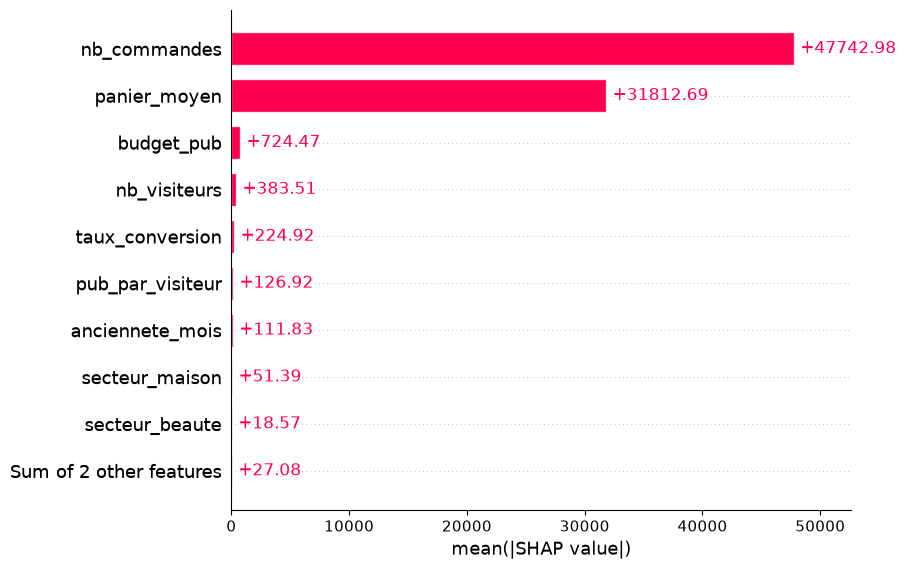

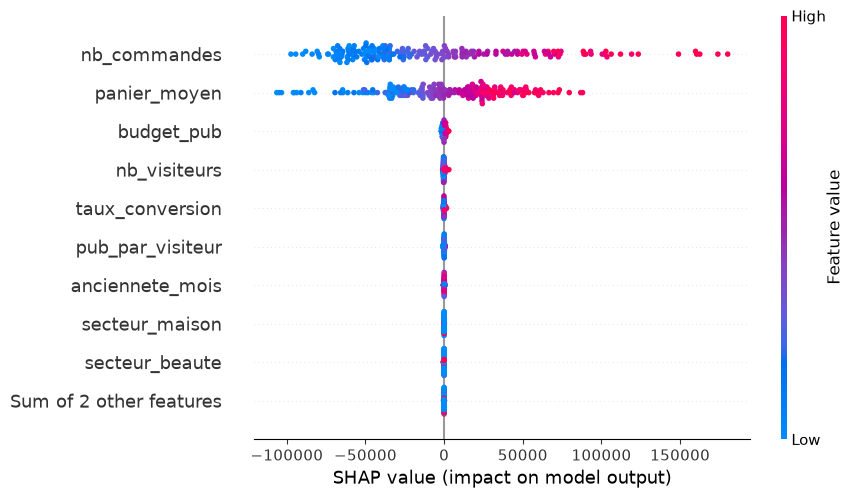

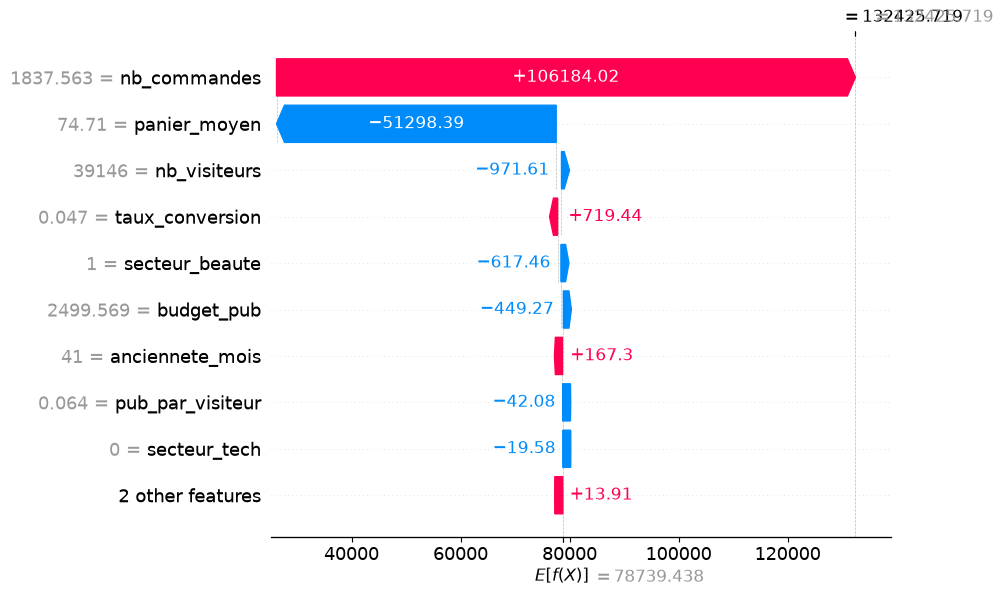

In [7]:
import shap

explainer = shap.TreeExplainer(best)       # explicateur spécial arbres (rapide)
shap_values = explainer(X_test)            # contributions pour chaque ligne du test

# 1. Vue globale : quelles features comptent le plus ?
shap.plots.bar(shap_values)

# 2. Vue détaillée : comment chaque feature influence le CA
shap.plots.beeswarm(shap_values)

# 3. Un seul e-commerçant : pourquoi CETTE prédiction ?
shap.plots.waterfall(shap_values[0])